<a href="https://colab.research.google.com/github/jojojojo-jo/LRP_analysis_resnet/blob/main/intermediate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#0. Import

Zennit: https://zennit.readthedocs.io/en/latest/tutorial/image-classification-vgg-resnet.html#4.3-LRP-with-custom-LayerMapComposite

In [ ]:
!pip install torch==2.9.0 torchvision==0.24.0 torchaudio==2.9.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 90.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 778.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/2

In [ ]:
!pip install zennit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 1.2 MB/s eta 0:00:00


In [ ]:
import torch
from torch import nn
from torch.nn import Linear
import torch.nn.functional as F

from itertools import islice

from PIL import Image

import torchvision
from torchvision import datasets, models, transforms
from torchvision.transforms import Compose, Resize, CenterCrop
from torchvision.transforms import ToTensor, Normalize
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights

from zennit.attribution import Gradient
from zennit.composites import EpsilonPlusFlat
from zennit.composites import SpecialFirstLayerMapComposite, NameMapComposite
from zennit.image import imsave

import os
import numpy as np
import matplotlib.pyplot as plt

#import torchinfo.summary
try:
  from torchinfo import summary
except:
  print("[INFO] Couldn't find torchinfo... installing it")
  !pip install -q torchinfo
  from torchinfo import summary

#import helper functions
try:
  from going_modular.going_modular import data_setup, engine
except:
  print(f"[INFO] Couldn't find going_modular scripts... downloading from GitHub")
  !git clone https://github.com/mrdbourke/pytorch-deep-learning
  !mv pytorch-deep-learning/going_modular .
  !rm -rf pytorch-deep-learning
  from going_modular.going_modular import data_setup, engine

[INFO] Couldn't find torchinfo... installing it
[INFO] Couldn't find going_modular scripts... downloading from GitHub
Cloning into 'pytorch-deep-learning'...
remote: Enumerating objects: 4410, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 4410 (delta 5), reused 2 (delta 2), pack-reused 4400 (from 2)
Receiving objects: 100% (4410/4410), 764.18 MiB | 34.57 MiB/s, done.
Resolving deltas: 100% (2661/2661), done.
Updating files: 100% (248/248), done.


In [ ]:
print(torch.__version__)

2.9.0+cu128


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

#1. Get data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile

from pathlib import Path

import requests

data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi_20_percent"

if image_path.is_dir():
  print(f"{image_path} directory exists")
else:
  print(f"Did not find {image_path} directory, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)

  with open(data_path / "pizza_steak_sushi_20_percent.zip", "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")
    print("Downloading data...")
    f.write(request.content)

  with zipfile.ZipFile(data_path / "pizza_steak_sushi_20_percent.zip", "r") as zip_ref:
    print("Unzipping data...")
    zip_ref.extractall(image_path)

  os.remove(data_path / "pizza_steak_sushi_20_percent.zip")

Did not find data/pizza_steak_sushi_20_percent directory, creating one...
Unzipping data...


In [ ]:
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi_20_percent/train'),
 PosixPath('data/pizza_steak_sushi_20_percent/test'))

In [ ]:
from numpy.matrixlib import test

weights = torchvision.models.ResNet18_Weights.DEFAULT
auto_transforms = weights.transforms()
print(f"Automatically created transforms: {auto_transforms}")

train_dataset = datasets.ImageFolder(train_dir, transform=auto_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=auto_transforms)
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=auto_transforms,
                                                                               batch_size=32)
train_dataloader, test_dataloader, class_names

Automatically created transforms: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


(<torch.utils.data.dataloader.DataLoader at 0x7b66a2f53b30>,
 ['pizza', 'steak', 'sushi'])

#2. Load model

In [ ]:
torch.manual_seed(42)

weights = torchvision.models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
for param in model.parameters():
    param.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(class_names))

model_path = '/content/drive/MyDrive/study/Project/models/best_model_plateau.pth'
model.load_state_dict(torch.load(model_path, map_location=torch.device('cpu')))
model = model.to(device)

model.eval()

print("Model loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


Model loaded successfully!


In [ ]:
# define the base image transform
transform_img = Compose([
    Resize(256),
    CenterCrop(224),
])
# define the normalization transform
transform_norm = Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
# define the full tensor transform
transform = Compose([
    transform_img,
    ToTensor(),
    transform_norm,
])

# load the image
image = Image.open('steak1.jpg')

# transform the PIL image and insert a batch-dimension
data = transform(image)[None]

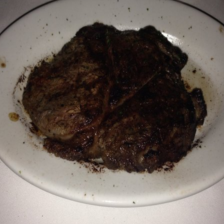

In [ ]:
display(transform_img(image))

#3. Intermediate gradients

In [ ]:
# Forcefully clear all dangling forward and backward hooks from the model
for module in model.modules():
    module._forward_hooks.clear()
    module._backward_hooks.clear()

with torch.no_grad():
  output = model(input)

pred_int = output.argmax(1).item()
print(pred_int)

1


In [ ]:
import torch
from torch.nn import Sequential, Conv2d, ReLU, Linear, Flatten

from zennit.attribution import Gradient
from zennit.composites import EpsilonPlusFlat

# setup the model and data
input = data

# make sure the input requires a gradient
input.requires_grad = True

# create a composite instance
composite = EpsilonPlusFlat()

# create a gradient attributor
attributor = Gradient(model, composite)

In [ ]:
# create a hook to keep track of intermediate outputs
def store_hook(module, input, output):
    # set the current module's attribute 'output' to the its tensor
    module.output = output
    # keep the output tensor gradient, even if it is not a leaf-tensor
    output.retain_grad()

target_layers = {
        'layer1': model.layer1,
        'layer2': model.layer2,
        'layer3': model.layer3,
        'layer4': model.layer4
    }

# enter the attributor's context to register the rule-hooks
with attributor:
    # register the store_hook AFTER the rule-hooks have been registered (by
    # entering the context) so we get the last output before the next module
    handles = [
        layer.register_forward_hook(store_hook) for layer in target_layers.values()
    ]
    # compute the relevance wrt. output/class 1
    output, relevance = attributor(input, torch.eye(len(class_names))[[1]])

# remove the hooks using store_hook
for handle in handles:
    handle.remove()

for name, layers in target_layers.items():
    print(f'{name}: {layers.output.grad}')

for handle in handles:
    handle.remove()

layer1: tensor([[[[ 1.6190e-03,  4.9054e-04,  9.4327e-04,  ...,  1.1315e-04,
            4.5545e-04,  8.6230e-05],
          [ 1.5852e-04,  9.2358e-04,  3.6656e-04,  ...,  8.8985e-05,
            7.8703e-05,  5.5524e-05],
          [ 0.0000e+00,  7.0655e-05,  2.5448e-04,  ...,  2.0695e-05,
            9.2979e-05,  8.3169e-06],
          ...,
          [-2.3574e-05, -8.4629e-05, -3.1286e-05,  ...,  1.6111e-04,
            7.7139e-05,  5.3289e-05],
          [-3.8671e-05, -2.9753e-05, -1.0940e-04,  ...,  5.9210e-05,
            1.9972e-04,  1.3846e-05],
          [-7.5759e-06, -3.1157e-05, -8.8607e-06,  ...,  5.2077e-05,
            2.9167e-05,  2.3762e-05]],

         [[ 2.8272e-03,  5.4014e-04,  1.5949e-03,  ...,  1.7670e-04,
            8.5636e-04,  1.2193e-04],
          [ 1.3797e-04,  1.9291e-04,  8.2254e-05,  ...,  6.0034e-05,
            8.1754e-05,  3.7903e-05],
          [ 1.3129e-03,  2.5275e-04,  3.2753e-03,  ...,  9.3143e-05,
            1.7064e-03,  5.5832e-05],
          ..

#4. Generate LRP Heatmap

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.ndimage
import torch
import torch.nn.functional as F
from matplotlib.colors import LinearSegmentedColormap


def plot_heatmap(
    layer_tensor, original_img_tensor, title="Crisp Layer Heatmap", auto_blur=False
):
    """Slightly smoothens intermediate layers to connect pixel gaps

    while strictly preserving the shapes and borders of the original relevance.
    """
    # 1. Get original image canvas dimensions
    img_h, img_w = original_img_tensor.shape[-2:]

    # 2. Collapse channels to get the spatial footprint
    relevance = layer_tensor.detach().cpu().squeeze()
    if relevance.dim() == 3:
        relevance = torch.sum(relevance, dim=0)

    # 3. Apply a TIGHT, subtle smoothing filter
    heatmap_raw = relevance.numpy()
    if auto_blur:
        # A tiny sigma (0.8) bridges the circle/box gaps without washing out the features
        heatmap_raw = scipy.ndimage.gaussian_filter(heatmap_raw, sigma=0.8)

    # Convert back to tensor for bilinear scaling
    relevance = torch.tensor(heatmap_raw).unsqueeze(0).unsqueeze(0)

    # 4. Upsample cleanly via Bilinear Interpolation
    relevance_resized = F.interpolate(
        relevance, size=(img_h, img_w), mode="bilinear", align_corners=False
    )
    heatmap = relevance_resized.squeeze().numpy()

    # 5. Prepare the original sushi image underlay
    img_np = original_img_tensor.detach().cpu().squeeze().numpy()
    if img_np.ndim == 3:
        img_np = np.transpose(img_np, (1, 2, 0))
    if img_np.max() > 1.0:
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())

    # 6. Recreate the signature Fiery Zennit 'coldnhot' colormap
    cdict_coldnhot = {
        "red": (
            (0.0, 0.0, 0.0),  # Negative peak has zero red
            (0.45, 0.0, 0.0),  # Negative slope stays dark
            (0.55, 0.0, 0.0),  # Midpoint boundary stays black
            (0.72, 0.8, 0.8),  # Deep fire red ignition
            (0.85, 1.0, 1.0),  # Vibrant orange
            (0.95, 1.0, 1.0),  # Hot yellow
            (1.0, 1.0, 1.0),  # Peak white hot-spots
        ),
        "green": (
            (0.0, 0.0, 0.0),  # Cleaned: Zero green at the negative peak turns cyan into dark blue
            (0.45, 0.0, 0.0),  # Neutral zone is dark
            (0.55, 0.0, 0.0),  # Midpoint boundary stays black
            (0.72, 0.0, 0.0),
            (0.85, 0.4, 0.4),  # Green introduces orange mix
            (0.95, 1.0, 1.0),  # High green creates yellow
            (1.0, 1.0, 1.0),
        ),
        "blue": (
            (0.0, 0.8, 0.8),  # Negative peak is a deep, rich dark blue
            (0.45, 0.0, 0.0),  # Drops cleanly to black before zero midpoint
            (0.55, 0.0, 0.0),  # Zero point safety zone
            (0.95, 0.0, 0.0),  # Positive fire zones contain no blue
            (1.0, 1.0, 1.0),  # White peak hot spots include full spectrum
        ),
    }
    coldnhot_cmap = LinearSegmentedColormap("fiery_coldnhot", cdict_coldnhot)

    # Normalize color limits symmetrically around zero
    vmax = np.percentile(np.abs(heatmap), 99.5)
    vmin = -vmax

    # 7. Render Canvas
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), facecolor="black")

    # Left Panel: Pure original sushi photograph
    axes[0].imshow(img_np)
    axes[0].set_title("Original Input Image", color="white", fontsize=12)
    axes[0].axis("off")

    # Right Panel: Crisp, interconnected heat overlay
    axes[1].imshow(img_np, alpha=0.8)
    im = axes[1].imshow(
        heatmap,
        cmap=coldnhot_cmap,
        vmin=vmin,
        vmax=vmax,
        alpha=0.8,
        interpolation="bilinear",  # Extra layer of smooth rendering inside matplotlib
    )
    axes[1].set_title(title, color="white", fontsize=12)
    axes[1].axis("off")

    # Colorbar
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.04)
    cbar.ax.yaxis.set_tick_params(color="white")
    plt.setp(plt.getp(cbar.ax.axes, "yticklabels"), color="white")

    plt.show()

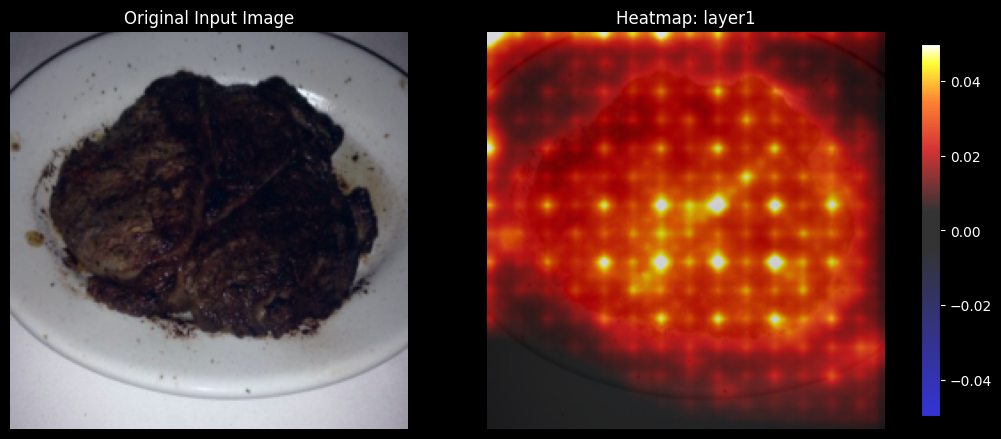

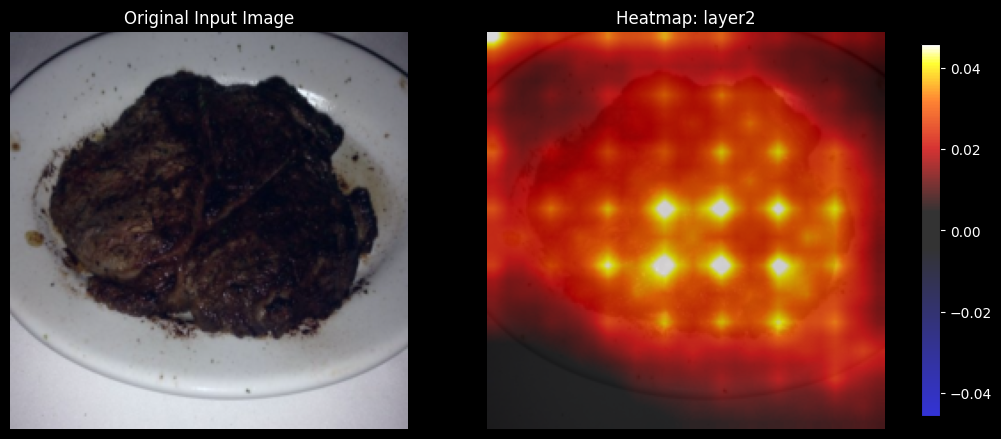

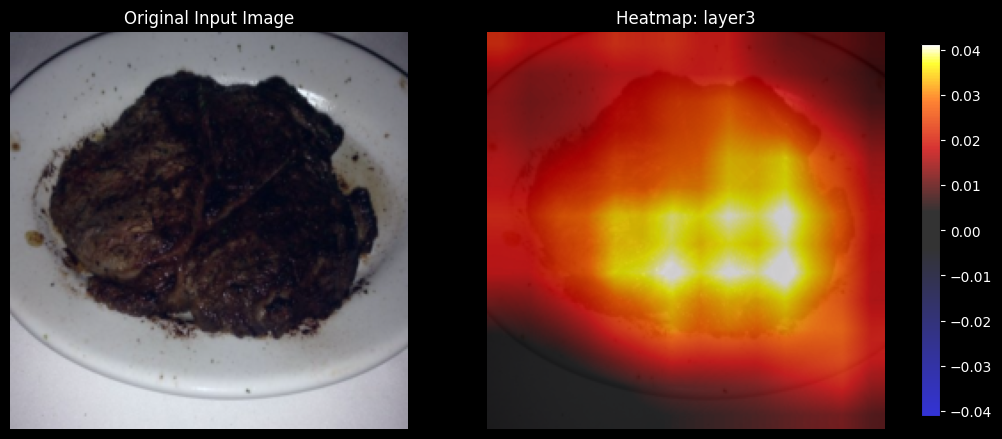

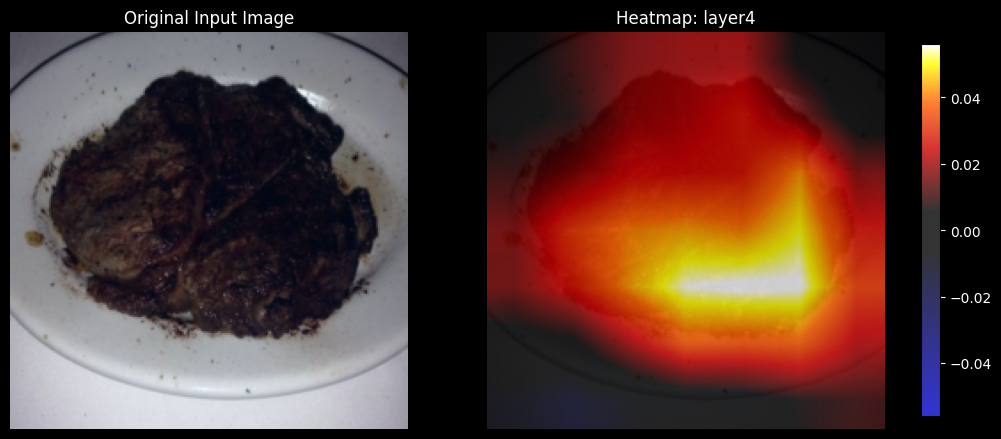

In [ ]:
for name, layer in target_layers.items():
    if layer.output.grad is not None:
        # Only slightly smooth out the early, ultra-sharp grids
        should_smooth = name in ["layer1", "layer2", "layer3"]

        plot_heatmap(
            layer_tensor=layer.output.grad,
            original_img_tensor=input,
            title=f"Heatmap: {name}",
            auto_blur=should_smooth,
        )